<div style="text-align: center; margin-bottom: 25px;">
    <div style="margin-bottom: 20px;">
        <img src="https://upload.wikimedia.org/wikipedia/fr/5/5f/Safran_-_logo_2016.png" style="height: 60px; width: auto; vertical-align: middle; margin: 0 20px;">
    </div>
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Implémentation de DeepViterbi</h1>
    </div>
</div>

## **1. Importation des modules**

In [44]:
import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt

from CC import *
from convolutif import *

from datetime import datetime

import tensorflow as tf
from keras import layers
from keras import models
from keras import callbacks
from keras import optimizers
from keras.models import Sequential
from sklearn.model_selection import train_test_split

## **2. Création du dataset**

#### **2.1. Données d'entraînement**

In [32]:
n = 50000
trame = 100
SNR = 2
N0 = 10**(-SNR/10)
Ec = 1/2


Y = rd.randint (0, 2, (n, trame, 1))
bruit = np.sqrt (N0/2) * np.random.randn(len(Y), trame, 2)
X = (-2 * np.array([cc2(h) for h in Y]) + 1) * np.sqrt(Ec) + bruit


xtrain, xtest, ytrain, ytest = train_test_split (X, Y, test_size = 0.20)

#### **2.2. Données de validation**

In [ ]:
n_val = 200000
trame_val = 100

yval = rd.randint (0, 2, (n_val, trame_val, 1))
N0 = 10**(-SNR/10)
bruit = np.sqrt (N0/2) * np.random.randn(len(yval), trame_val, 2)
xval = (-2 * np.array([cc2(h) for h in yval]) + 1) * np.sqrt(Ec) + bruit

#### **2.3. Données de test**

In [33]:
n_test = 200000
trame_test = 100

ytest = rd.randint (0, 2, (n_test, trame_test, 1))
N0 = 10**(-SNR/10)
bruit = np.sqrt (N0/2) * np.random.randn(len(ytest), trame_test, 2)
xtest = (-2 * np.array([cc2(h) for h in ytest]) + 1) * np.sqrt(Ec) + bruit

## **3. Visualisation du dataset**

In [34]:
print (f" xtrain.shape : {xtrain.shape}")
print (f" ytrain.shape : {ytrain.shape}")

 xtrain.shape : (40000, 100, 2)
 ytrain.shape : (40000, 100, 1)


## **4. Création du modèle**

In [35]:
model = Sequential ()

model.add (layers.Input (shape = (trame, 2)))

model.add (layers.Dropout (0.2))
model.add (layers.Bidirectional (layers.SimpleRNN (64, return_sequences = True)))
model.add (layers.BatchNormalization ())
model.add (layers.Dropout (0.2))
model.add (layers.Bidirectional (layers.SimpleRNN (64, return_sequences = True)))
model.add (layers.BatchNormalization ())
model.add (layers.Dense (128, activation = "sigmoid"))
model.add (layers.Dense (128, activation = "sigmoid"))

model.add (layers.Dense (1, activation = "sigmoid"))

model.summary ()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout_4 (Dropout)             │ (None, 100, 2)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 100, 128)       │         8,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 100, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 100, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 100, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100, 128)       │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100, 128)       │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100, 1)         │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,457 (263.50 KB)

 Trainable params: 66,945 (261.50 KB)

 Non-trainable params: 512 (2.00 KB)

## **5. Entraînement du modèle**

#### **5.1. Gaussian Annealing technique**

In [36]:
sigma_0 = 0.05
P = 30

class SimulatedAnnealingCallback(tf.keras.callbacks.Callback):
    def __init__(self, sigma_0, P):
        super(SimulatedAnnealingCallback, self).__init__()
        self.sigma_0 = sigma_0
        self.P = P
        self.current_epoch = 0
 
    def on_epoch_end(self, epoch, logs=None):
        self.current_epoch = epoch
        sigma_p = self.sigma_0 * (1 - epoch / self.P)
 
        for var in self.model.trainable_variables:
            noise = tf.random.normal(shape=var.shape, stddev=sigma_p)
            var.assign_add(noise)
 
        print(f"   Epoch {epoch+1}/{self.P} - Applied SA noise (σ={sigma_p:.4f})")

sa_callback = SimulatedAnnealingCallback(sigma_0, P)

#### **5.2. Reached Accuracy**

In [37]:
accurate = 0.981

class StopWhenAccuracyReached(tf.keras.callbacks.Callback):
    def __init__(self, target_accuracy):
        super().__init__()
        self.target_accuracy = target_accuracy

    def on_epoch_end(self, epoch, logs=None):
        val_acc = logs.get("val_accuracy")
        if val_acc is not None and val_acc >= self.target_accuracy:
            print(f"\n Accuracy {val_acc:.4f} atteinte à l'époque {epoch + 1}, arrêt de l'entraînement.")
            self.model.stop_training = True  


Target = StopWhenAccuracyReached(accurate)

#### **5.2. Callback keras**

In [38]:
EarlyStopping = callbacks.EarlyStopping (monitor = "val_accuracy", patience = 1)
TensorBoard = callbacks.TensorBoard (log_dir = "RNN.keras", histogram_freq = 1)
CheckPoint = callbacks.ModelCheckpoint (filepath = "RNN.keras", monitor = "val_accuracy", save_best_only = True, verbose = 0)
ReduceLR = callbacks.ReduceLROnPlateau (monitor = "val_loss", factor = 0.1, patience = 10)

#### **5.3. Optimiseurs**

In [39]:
optimizerA = optimizers.Adam (learning_rate = 0.001394108, clipnorm = 1.)
optimizerB = optimizers.RMSprop (learning_rate = 0.001394108, clipnorm = 1.)

#### **5.4. Entraînement**

In [40]:
model.compile (optimizer = optimizerA, loss = "bce", metrics = ["accuracy"])

history = model.fit (xtrain, 
                     ytrain,
                     epochs = 30, 
                     verbose = 1, 
                     validation_data = (xval, yval), 
                     callbacks = [CheckPoint, Target], 
                     batch_size = 16)

Epoch 1/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 164s 65ms/step - accuracy: 0.8584 - loss: 0.2926 - val_accuracy: 0.9677 - val_loss: 0.0894
Epoch 2/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 167s 67ms/step - accuracy: 0.9117 - loss: 0.2057 - val_accuracy: 0.9764 - val_loss: 0.0674
Epoch 3/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 170s 68ms/step - accuracy: 0.9186 - loss: 0.1915 - val_accuracy: 0.9782 - val_loss: 0.0634
Epoch 4/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 164s 66ms/step - accuracy: 0.9209 - loss: 0.1863 - val_accuracy: 0.9774 - val_loss: 0.0639
Epoch 5/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 164s 66ms/step - accuracy: 0.9225 - loss: 0.1829 - val_accuracy: 0.9794 - val_loss: 0.0579
Epoch 6/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 206s 82ms/step - accuracy: 0.9230 - loss: 0.1819 - val_accuracy: 0.9793 - val_loss: 0.0584
Epoch 7/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 230s 92ms/step - accuracy: 0.9238 - loss: 0.1801 - val_accuracy: 0.9797 - val_loss: 0.0570
Epoch 8/30
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 227s 91ms/step - accuracy: 

## **6. Visualisation des performances**

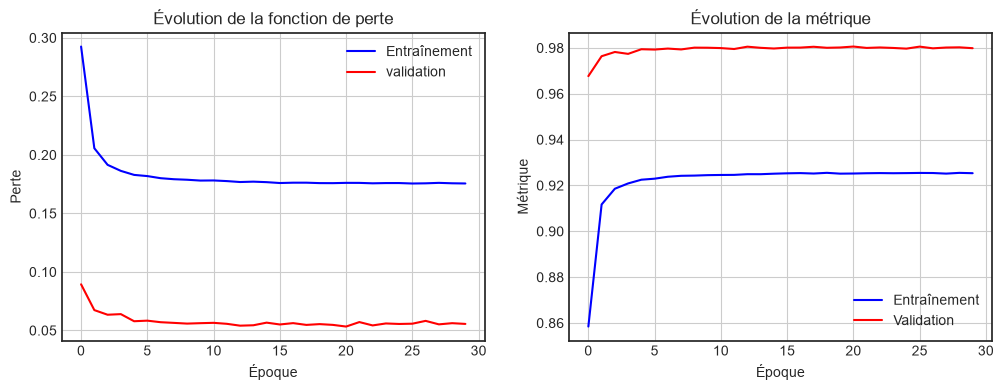

In [42]:
trainloss = history.history ["loss"]
testloss = history.history ["val_loss"]
trainaccuracy = history.history ["accuracy"]
testaccuracy = history.history ["val_accuracy"]

plt.style.use('seaborn-v0_8-white' if 'seaborn-v0_8-white' in plt.style.available else 'default')
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot (range (len (trainloss)), trainloss, "b", label = "Entraînement")
axs[0].plot (range (len (testloss)), testloss, "r", label = "validation")
axs[0].set_title ("Évolution de la fonction de perte")
axs[0].set_xlabel ("Époque")
axs[0].set_ylabel ("Perte")
axs[0].legend ()
axs[0].grid (True)


axs[1].plot (range (len (trainaccuracy)), trainaccuracy, "b", label = "Entraînement")
axs[1].plot (range (len (testaccuracy)), testaccuracy, "r", label = "Validation")
axs[1].set_title ("Évolution de la métrique")
axs[1].set_xlabel ("Époque")
axs[1].set_ylabel ("Métrique")
axs[1].legend ()
axs[1].grid (True)
#axs[1].savefig(f"Loss.png", dpi=300)

plt.show ()

## **7. Chargement du modèle**

In [45]:
model = models.load_model("RNN.keras")

## **8. Validation du modèle**

In [46]:
loss, accuracy = model.evaluate (xtest, ytest)
print (" ")
print (f" Le modèle a une précision de {np.round (accuracy*100, 2)} pourcent pour un SNR de {SNR}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9806 - loss: 0.0535
 
 Le modèle a une précision de 98.06 pourcent pour un SNR de 2
